In [65]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
from PIL import Image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [66]:
# [추가] 재현성 설정
#   시드를 고정하지 않으면 같은 코드를 다시 돌려도 결과가 달라져서
#   수정이 효과가 있었는지 판단할 수 없다
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if hasattr(torch, "xpu") and torch.xpu.is_available():
    torch.xpu.manual_seed_all(SEED)

print(f"seed 고정: {SEED}")

seed 고정: 42


In [67]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [68]:
base_path = r"D:\kdt_dataset"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [69]:
# [수정] 위치 이동: ImageFolder 셀보다 위로 올림
#   (원래는 아래에 있어서 커널 재시작 후 위에서부터 실행하면
#    NameError: name 'train_transform' is not defined 발생)
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경하는 것부터 시작
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(), # 반전
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경하는 것부터 시작
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(), # 반전
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

In [70]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

In [71]:
total_size = len(train_dataset) + len(test_dataset)
total_size

300

In [72]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

## CNN을 활용해서 도형 분류하기 실습

#### 현재 데이터셋 주소를 받아와서 ImageFolder를 활용해 학습 및 테스트 데이터셋에 저장함

In [73]:
len(train_dataset), len(test_dataset)

(240, 60)

In [74]:
# [추가] 검증(validation) 셋 분리
#   기존에는 test_dataset을 매 에폭 평가에 썼는데, 그 결과를 보고
#   에폭 수나 채널 수를 조정하면 test 셋에 맞춰 튜닝한 셈이 되어 성능이 과대평가된다.
#   train을 8:2로 나눠 val을 만들고, test는 맨 마지막 최종 평가에만 사용한다.
n_total = len(train_dataset)
n_train = int(n_total * 0.8)
n_val = n_total - n_train        # 반올림 오차로 합이 안 맞는 것을 막기 위해 나머지로 계산

train_subset, val_subset = random_split(
    train_dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)   # 매번 같은 분할
)

print(f"train: {len(train_subset)} / val: {len(val_subset)} / test: {len(test_dataset)}")

train_dataloader = DataLoader(train_subset, batch_size=64, shuffle=True)   # [수정] train_dataset -> train_subset
val_dataloader = DataLoader(val_subset, batch_size=64)                     # [추가]
test_dataloader = DataLoader(test_dataset, batch_size=64)

train: 192 / val: 48 / test: 60


In [75]:
imgs, labels = next(iter(train_dataloader))

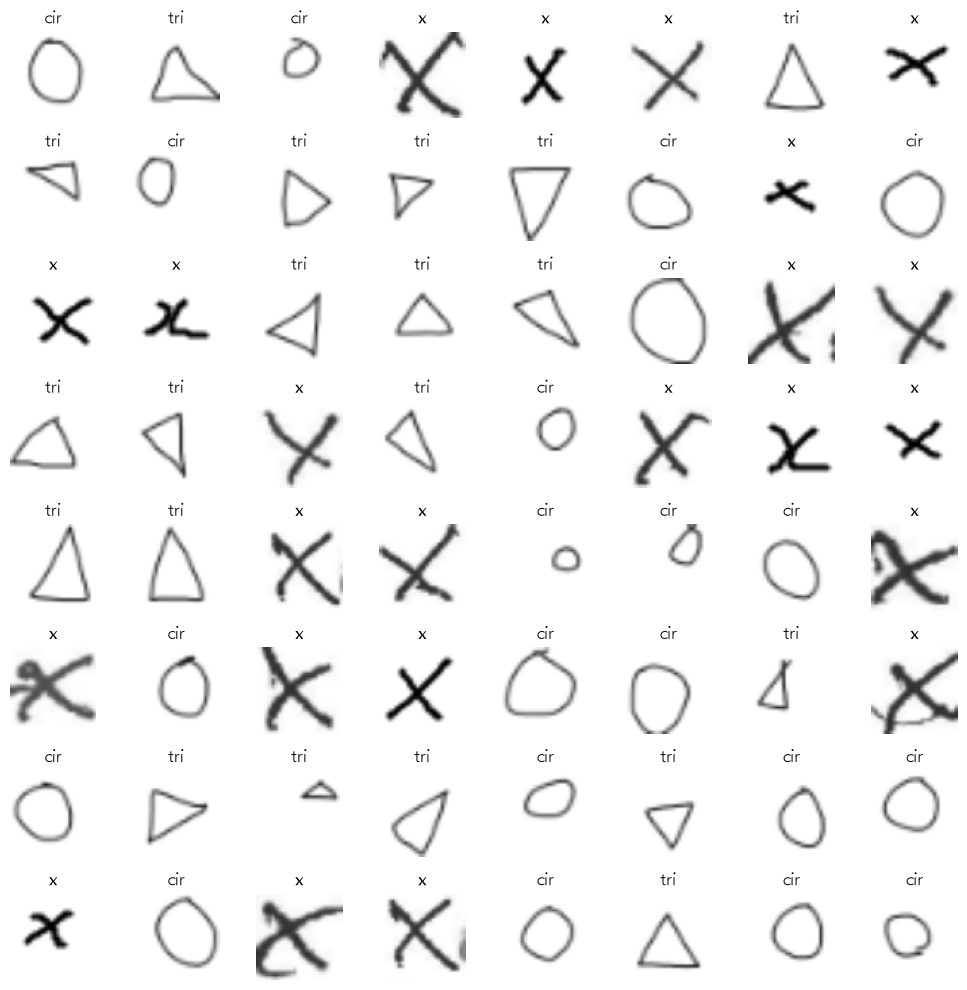

In [76]:
fig, axes = plt.subplots(8, 8, figsize=(10, 10))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    # [수정] reshape(64, 64) -> squeeze() : 이미지 크기가 바뀌어도 동작
    # [수정] 역정규화 추가 : Normalize(0.5, 0.5)로 [-1, 1] 범위가 되어
    #        그대로 imshow하면 matplotlib이 클리핑해 대비가 뭉개짐
    ax.imshow(img.squeeze() * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [77]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: xpu


## CNN 모델 준비

In [78]:
imgs.shape

torch.Size([64, 1, 64, 64])

In [79]:
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNenuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifer = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # 32, 32
            nn.Dropout2d(0.25),            # [수정] Dropout -> Dropout2d (conv 뒤에는 채널 단위가 적절)

            nn.Conv2d(16, 32, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # [수정] 주석 32, 32 -> 16, 16
            nn.Dropout2d(0.25),            # [수정] Dropout -> Dropout2d

            nn.Conv2d(32, 64, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # [수정] 주석 32, 32 -> 8, 8
            nn.Dropout2d(0.25),            # [수정] Dropout -> Dropout2d
        )
        self.linear = nn.Linear(64*8*8, 3)   # 64 x 8 x 8 = 4096, 출력 3 (cir/tri/x)

    def forward(self, x):
        x = self.classifer(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [80]:
model = ConvNenuralNetwork().to(device)

In [81]:
model

ConvNenuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifer): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout2d(p=0.25, inplace=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout2d(p=0.25, inplace=False)
    (12): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (13): ReLU()
    (14): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (15): ReLU()
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (17): Dropout2d(p=0.25, inp

In [82]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [83]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=10):
    model.train()
    total = 0
    sum_loss = 0.0
    sum_acc = 0.0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # [수정] imgs.size() -> imgs.size(0)
        #   size()는 torch.Size([64, 1, 64, 64]) 튜플을 반환하므로
        #   float * tuple 이 되어 TypeError가 발생함
        batch_size = imgs.size(0)

        sum_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        sum_acc += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return sum_loss / total, sum_acc / total

In [84]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    sum_loss = 0.0
    sum_acc = 0.0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            outputs = model(imgs) # 순전파
            loss = criterion(outputs, labels) # 손실계산

            batch_size = imgs.size(0)
            sum_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            sum_acc += (preds == labels).sum().item()
            total += batch_size

    return sum_loss / total, sum_acc / total

In [85]:
epochs = 50

# [추가] 최적 모델 저장 / 조기 종료용 변수
best_val_loss = float("inf")
patience = 10        # val loss가 10 에폭 연속 개선되지 않으면 중단
bad_epochs = 0

# [추가] 에폭별 지표 기록 (학습 곡선용) - print만 하면 흘려보내게 된다
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for i in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        log_step=0                   # [수정] 배치별 로그 끔 (에폭 단위로만 출력)
    )

    # [수정] test_dataloader -> val_dataloader
    #   test 셋은 하이퍼파라미터 조정에 쓰면 성능이 과대평가되므로 마지막에 한 번만 사용
    val_loss, val_acc = evaluate(
        model=model,
        dataloader=val_dataloader,
        criterion=criterion,
        device=device
    )

    # [추가] 지표 기록
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {i + 1}/{epochs} | "
          f"Train Loss {train_loss:.4f} Acc {train_acc * 100:.2f} | "
          f"Val Loss {val_loss:.4f} Acc {val_acc * 100:.2f}")

    # [추가] 최적 모델 저장 - 마지막 에폭이 최고 성능인 경우는 드물다
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        bad_epochs = 0
        torch.save(model.state_dict(), "best_model.pth")
        print(f"  -> best 갱신 (val_loss {val_loss:.4f}), best_model.pth 저장")
    else:
        # [추가] 조기 종료
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"  -> {patience} 에폭 동안 개선 없음. 조기 종료")
            break

# [추가] 학습 종료 후 best 가중치로 되돌리기
model.load_state_dict(torch.load("best_model.pth", weights_only=True))
print(f"\nbest val loss: {best_val_loss:.4f} / best 가중치 복원 완료")

Epoch 1/50 | Train Loss 1.1021 Acc 35.42 | Val Loss 1.1071 Acc 22.92
  -> best 갱신 (val_loss 1.1071), best_model.pth 저장
Epoch 2/50 | Train Loss 1.0961 Acc 36.46 | Val Loss 1.0973 Acc 43.75
  -> best 갱신 (val_loss 1.0973), best_model.pth 저장
Epoch 3/50 | Train Loss 1.0613 Acc 54.69 | Val Loss 1.0051 Acc 56.25
  -> best 갱신 (val_loss 1.0051), best_model.pth 저장
Epoch 4/50 | Train Loss 0.9462 Acc 60.42 | Val Loss 0.7658 Acc 56.25
  -> best 갱신 (val_loss 0.7658), best_model.pth 저장
Epoch 5/50 | Train Loss 0.7257 Acc 67.71 | Val Loss 0.6694 Acc 56.25
  -> best 갱신 (val_loss 0.6694), best_model.pth 저장
Epoch 6/50 | Train Loss 0.6081 Acc 68.23 | Val Loss 0.6136 Acc 56.25
  -> best 갱신 (val_loss 0.6136), best_model.pth 저장
Epoch 7/50 | Train Loss 0.5130 Acc 69.27 | Val Loss 0.4309 Acc 79.17
  -> best 갱신 (val_loss 0.4309), best_model.pth 저장
Epoch 8/50 | Train Loss 0.4707 Acc 68.75 | Val Loss 0.3988 Acc 70.83
  -> best 갱신 (val_loss 0.3988), best_model.pth 저장
Epoch 9/50 | Train Loss 0.4111 Acc 75.00 | Val L

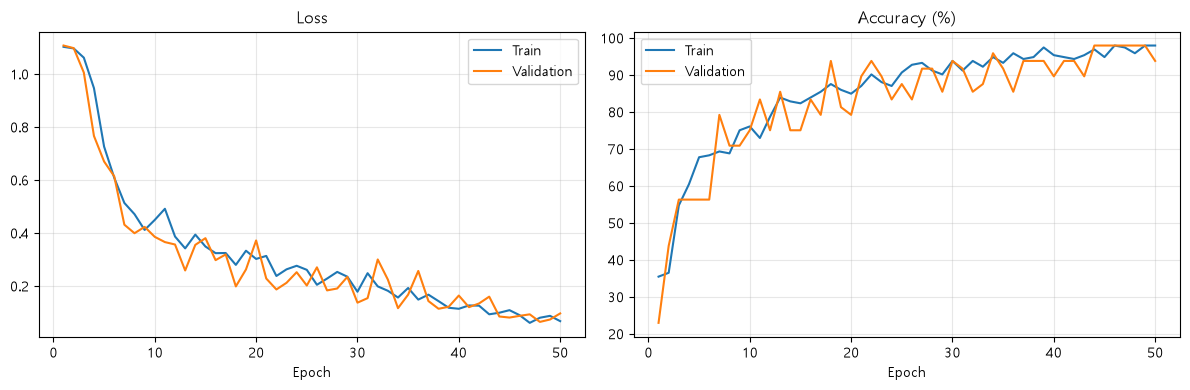

In [86]:
# [추가] 학습 곡선 - 과적합이 언제 시작됐는지 눈으로 확인
#   Train 곡선은 내려가는데 Validation 곡선이 올라가기 시작하는 지점이 과적합 시작점
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, history["train_loss"], label="Train")
axes[0].plot(epochs_ran, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, [a * 100 for a in history["train_acc"]], label="Train")
axes[1].plot(epochs_ran, [a * 100 for a in history["val_acc"]], label="Validation")
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Test Loss: 0.4842  Test Accuracy: 85.00%

              precision    recall  f1-score   support

         cir       0.76      0.80      0.78        20
         tri       0.79      0.75      0.77        20
           x       1.00      1.00      1.00        20

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



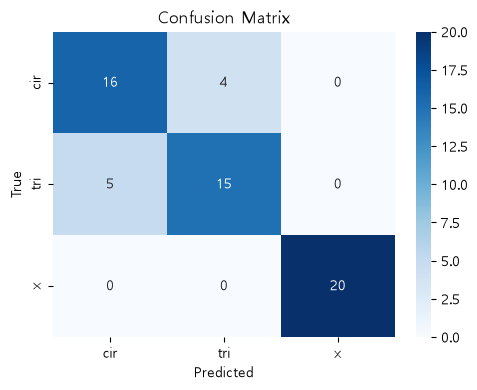

In [87]:
# [추가] 최종 평가 - test 셋은 여기서 처음, 그리고 한 번만 사용
model.eval()

y_true_all = []
y_pred_all = []

with torch.no_grad():
    for batch_imgs, batch_labels in test_dataloader:
        outputs = model(batch_imgs.to(device))
        _, batch_preds = outputs.max(1)
        y_pred_all.extend(batch_preds.cpu().tolist())
        y_true_all.extend(batch_labels.tolist())

test_loss, test_acc = evaluate(model, test_dataloader, criterion, device)
print(f"Test Loss: {test_loss:.4f}  Test Accuracy: {test_acc * 100:.2f}%\n")

# [추가] 클래스별 정밀도/재현율 - 정확도 숫자 하나로는 어떤 도형을 틀리는지 알 수 없다
target_names = [class_dict[i] for i in range(len(class_dict))]
print(classification_report(y_true_all, y_pred_all, target_names=target_names))

# [추가] 혼동 행렬 - 어떤 클래스를 어떤 클래스로 착각하는지
cm = confusion_matrix(y_true_all, y_pred_all)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

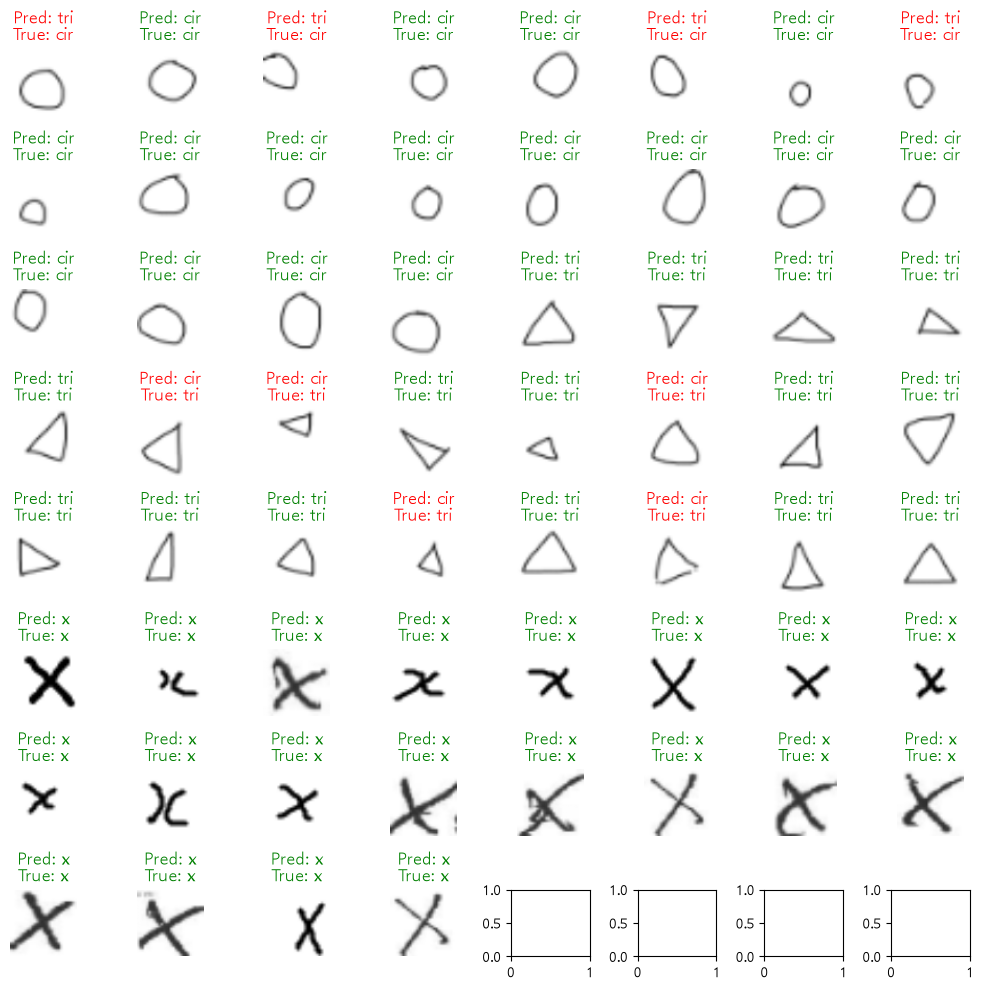

In [88]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1) # _는 첫번째 변수는 사용하지 않겠다는 뜻

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(8, 8, figsize=(10, 10))   # [수정] figsize (16,8) -> (14,14) : 6x6인데 세로가 짧아 제목이 겹침

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    # [수정] 역정규화 추가 : Normalize(0.5, 0.5)로 [-1, 1] 범위가 되므로
    #        그대로 imshow하면 matplotlib이 클리핑해 대비가 뭉개짐
    ax.imshow(img.squeeze() * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.tight_layout()   # [추가] 제목 겹침 방지
plt.show()

예측: x, 확률: 100.00


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

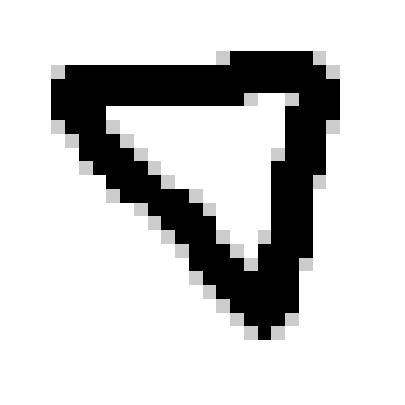

In [89]:
img_path = r"D:\kdt_dataset\dd.png"

shape = Image.open(img_path).convert("RGB")
input_tensor = test_transform(shape)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

    print(f"예측: {pred_class}, 확률: {confidence:.2f}")

plt.subplots(figsize=(10, 5))
plt.imshow(shape)
plt.axis("off")

타겟 레이어: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
예측 결과: x (확률: 100.0%, 클래스 번호: 2)


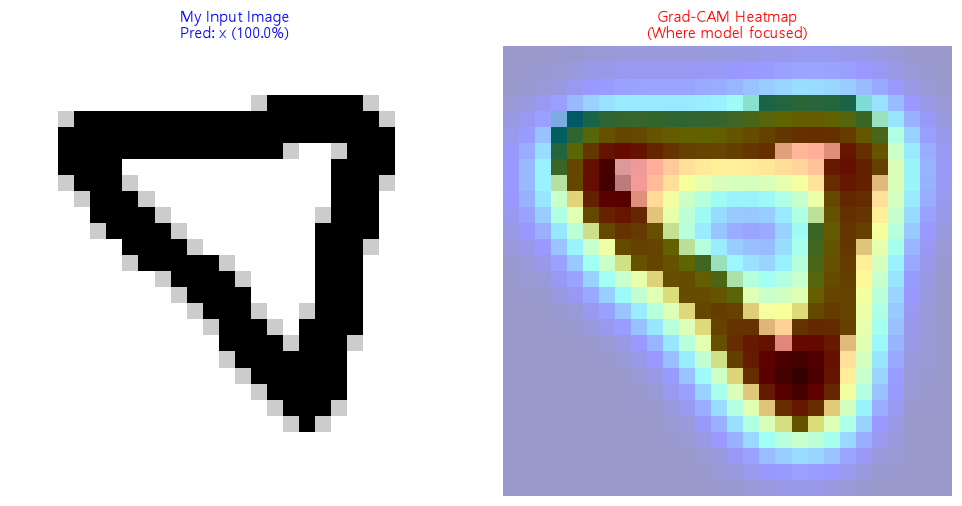

In [92]:
# 훅(Hook)을 사용하여 마지막 Convolution 층의 활성화 값과 그래디언트 추출 준비
activations = None
gradients = None

def forward_hook(module, input, output):
  global activations
  # [수정] .detach() 추가 : 히트맵 계산에 autograd 그래프가 필요 없고,
  #        full_backward_hook이 감싼 출력을 그대로 두면 뒤에서 수정할 때 오류가 남
  activations = output.detach()

def backward_hook(module, grad_input, grad_output):
  global gradients
  gradients = grad_output[0].detach()   # [수정] .detach() 추가


# 우리 모델의 classifer 안에서 마지막 Conv 레이어 지정
# [수정] model.classifier -> model.classifer
#   클래스 정의(셀 17)의 속성명이 오타로 'classifer'(i 빠짐)여서 AttributeError가 났음.
#   저장된 best_model.pth의 키도 'classifer.N.weight'라 지금 이름을 유지해야 함
# [수정] [-5] -> 타입으로 검색
#   Sequential 길이가 18이라 [-5]는 Conv2d가 아니라 ReLU였음.
#   인덱스를 손으로 세면 모델을 조금만 바꿔도 깨지므로 isinstance로 찾는다
conv_layers = [m for m in model.classifer if isinstance(m, nn.Conv2d)]
target_layer = conv_layers[-1]          # 마지막 Conv2d = Conv2d(64, 64)
print(f"타겟 레이어: {target_layer}")

target_layer.register_forward_hook(forward_hook)
# [수정] register_backward_hook -> register_full_backward_hook (구 API는 deprecated)
target_layer.register_full_backward_hook(backward_hook)

# [추가] Grad-CAM은 역전파가 필요하므로 no_grad를 쓰지 않는다.
#        단 Dropout은 꺼야 하므로 eval 모드로 전환
model.eval()

# 테스트할 이미지 경로 설정 및 전처리 적용
original_image = Image.open(img_path).convert("RGB")

# test_transform 활용
input_tensor = test_transform(original_image).unsqueeze(0).to(
    device
)  # (C, H, W) -> (1, C, H, W)

# 순전파 및 추론
output = model(input_tensor)
probs = F.softmax(output, dim=1)[0]
pred_idx = torch.argmax(probs).item()
pred_class = class_dict[pred_idx]  # 클래스 이름 딕셔너리 (예: {0: 'cir', ...})
confidence = probs[pred_idx].item() * 100

print(f"예측 결과: {pred_class} (확률: {confidence:.1f}%, 클래스 번호: {pred_idx})")

# Grad-CAM 역전파 및 히트맵 계산
model.zero_grad()
class_score = output[0, pred_idx]
class_score.backward()

# 채널별 중요도 가중치 계산 (GAP 성향 반영)
pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])          # (C,)

# [수정] for 루프 + in-place 곱셈을 브로드캐스팅으로 대체
#   기존 activations[:, i, :, :] *= ... 는 훅이 감싼 텐서를 제자리에서 수정해
#   "is a view and is being modified inplace" 오류를 일으킬 수 있고 느리다
weighted_activations = activations[0] * pooled_gradients[:, None, None]   # (C, H, W)

heatmap = torch.mean(weighted_activations, dim=0).cpu().numpy()
heatmap = np.maximum(heatmap, 0)  # ReLU 적용 (양수 기여도만)
if heatmap.max() != 0:
    heatmap /= heatmap.max()  # 0~1 정규화

# PIL을 이용해 히트맵 크기를 원본 이미지 크기에 맞게 조절
heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_pil = Image.fromarray(heatmap_uint8).resize(
    original_image.size, Image.Resampling.BILINEAR
)

# Matplotlib으로 원본 이미지와 Grad-CAM 오버레이 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 첫 번째: 원본 이미지 및 예측 결과
axes[0].imshow(original_image)
axes[0].set_title(f"My Input Image\nPred: {pred_class} ({confidence:.1f}%)", fontsize=11, color="blue",)
axes[0].axis("off")

# 두 번째: 원본 위에 히트맵 겹치기 (alpha=0.4로 반투명 효과)
axes[1].imshow(original_image)
axes[1].imshow(heatmap_pil, cmap="jet", alpha=0.4)  # jet 컬러맵으로 무지개빛 히트맵 표현
axes[1].set_title(f"Grad-CAM Heatmap\n(Where model focused)", fontsize=11, color="red")
axes[1].axis("off")

plt.tight_layout()
plt.show()